# Caso base de aprendizaje: control óptimo advección–difusión (Manzoni–Quarteroni–Salsa 2021) con RBF-FD + gradiente conjugado

**Objetivo.** Tomar un problema de control óptimo *resuelto en el libro* (Manzoni, Quarteroni & Salsa,
*Optimal Control of PDEs*, Springer 2021, clave `manzoni2021optimal`), resolverlo con **nuestras
herramientas** —discretización **RBF-FD (BFR)** + **método adjunto discreto** + **gradiente
conjugado (CG)**— y **validarlo** contra una discretización independiente (FEM $\mathbb P_1$, el método
del libro). Después damos un paso hacia nuestro problema real: controlar **tasas de extracción de pozos**
(control escalar, sumidero bilineal $u_i\,\psi_i(x)\,y$, cotas $0\le u_i\le u_{\max}$) con **CG no lineal proyectado**.

| Parte | Problema | Control | Optimizador | Relación con la tesis |
|---|---|---|---|---|
| A | Graetz (libro §6.5.1, Test case 2, ec. 6.65) | flujo en frontera $u\in L^2(\Gamma_c)$ | CG lineal precondicionado | adjunto/gradiente, condiciones de Neumann, validación |
| B | Canal con pluma + 4 pozos (inspirado en libro §1.3 «chimeneas») | tasas $u_i\ge 0$ | CG no lineal (PR+) proyectado vs L-BFGS-B | mismo tipo de control que nuestras $Q_{out}$ |

### Resumen de hallazgos (detalle en cada sección)
1. **Lectura de la condición de frontera.** Tal como está escrita en el libro (sin $\mu$) el problema es coercivo y
   estable. Leerla con $\mu$ («conormal») cambia el problema: $y_0$ pasa de $\max\approx1.12$ a $\approx2900$ (§1.1, §3.2).
2. **La Tabla 6.2 no es reproducible en valor absoluto** y es internamente incoherente: $J(a)>J(b)$ con
   $\Omega_0^1\subset\Omega_0^2$. Por eso la referencia cuantitativa es **nuestro FEM independiente**, no la tabla.
3. **RBF-FD sin nodos fantasma da un control óptimo espurio** cuando el control está en una frontera Neumann: el
   estado está bien, pero el optimizador explota modos oscilantes que la colocación amplifica. Su $\hat u$, metido
   en el FEM, casi no reduce $J$. **Con nodos fantasma** (como en la tesis) el control converge al del FEM (§6.3).
4. Con control **interior** (pozos, Parte B) RBF-FD y FEM coinciden sin trucos especiales.
5. **CG** (lineal o no lineal con búsqueda de Wolfe) es la herramienta correcta; Armijo solo no basta (§7.1).
6. **Benchmark de referencia (§11).** Contra el límite continuo (FEM graduado + Richardson) el error de $J^*$ a
   $h=1/40$ es 0.7–7 % en RBF-FD uniforme: la comparación de §6 era entre discretizaciones de la misma retícula.
   $J^*$ converge sólo con orden 1 en retícula uniforme por la singularidad de las esquinas $(1,0)$, $(1,1)$.

**Ejemplos del libro revisados:** §1.3 chimeneas (el más parecido en concepto, sin números), **§6.5.1 Test case 2**
(único de advección–difusión con números → caso base), §6.7/§6.9 (Laplace/difusión–reacción, con cotas),
**§8.3** (calor transitorio, Tablas 8.2–8.3 → siguiente peldaño, ver §9), §1.4 y §6.2.4 (sólo formulación).

## Ficha de lectura

**El problema, en palabras (libro §6.5.1, *Test case 2*, ec. 6.65).** Un fluido corre por un canal largo
($4\times1$) con el perfil parabólico de Poiseuille (campo de Graetz) y transporta una sustancia (o calor) $y$ que
entra con valor 1. En las paredes del tramo final ($x_1>1$) se puede inyectar o extraer flujo de esa sustancia: ese
flujo de pared $u$ es el control. Se quiere que en una zona aguas abajo $\Omega_0$ el perfil se parezca a un blanco
$z_d$ (constante 2 o parabólico) gastando poco control ($\beta=10^{-3}$). Es advección–difusión estacionaria con
control en una frontera de Neumann: la misma estructura de optimalidad que la tesis (adjunto con la advección
invertida, observación parcial y regularización de Tikhonov).

**Cómo lo resuelve el libro.** FEM $\mathbb P_1$ (11 028 vértices) y BFGS; da la Tabla 6.2 ($J$ inicial y óptimo de los
casos a–d) y las Figs. 6.3–6.5.

**Cómo lo implementamos (§2–5).** (i) RBF-FD (PHS $r^3$, grado 3, 30 vecinos) con **nodos fantasma** en las
fronteras de Neumann, como el simulador; (ii) un FEM $\mathbb P_1$ independiente escrito desde cero, que sirve de
referencia; (iii) adjunto **discreto** (discretizar y luego optimizar) verificado con el test de Taylor; (iv) gradiente
conjugado precondicionado con la matriz de masa del control.

**Cómo comparamos (§6, §11).** Con el libro, sólo cualitativamente: su Tabla 6.2 es incoherente ($J(a)>J(b)$
con $\Omega_0^1\subset\Omega_0^2$) y su estado inicial no se reproduce con ninguna lectura de la condición de
frontera (§1.1). La comparación cuantitativa es contra **nuestro FEM**, y la referencia continua sale de un FEM
graduado con Richardson.

| resultado | valor |
|---|---|
| RBF-FD vs FEM (misma retícula $h=1/40$) | $J(u_0)$ <0.3 %, $J^*$ <2 % |
| error de $J^*$ RBF-FD frente al continuo, $h=1/40$ | 7.3 / 6.0 / 2.2 / 0.8 % (a–d); orden ≈1 por la esquina |
| sin nodos fantasma | óptimo **espurio** ($J^*$ hasta 2.2× menor, pero $J_{FEM}(\hat u)\approx J(u_0)$) |
| Parte B (4 pozos, control bilineal) | RBF-FD = FEM a <1 % |
| iteraciones | CG 6–7, L-BFGS 14–30, descenso máximo 77–183, BFGS del libro 48–87 |

**Mapa:** §1 problema del libro y lectura de la frontera · §2 discretizaciones · §3 verificaciones · §4 adjunto y
Taylor · §5 CG · §6 resultados y comparación · §7 Parte B (pozos) · §8–10 valoración y qué trasladar a la tesis ·
§11 benchmark (`graetz_benchmark.py`).

## 1. El problema del libro (§6.5.1, ec. 6.65)

$$
\min_{u\in L^2(\Gamma_c)}\ \tilde J(y,u)=\frac12\int_{\Omega_0}(y-z_d)^2\,dx+\frac{\beta}{2}\int_{\Gamma_c}u^2\,d\sigma ,
\qquad \beta=10^{-3}
$$
sujeto a
$$
\begin{cases}
-\operatorname{div}(\mu\nabla y)+\operatorname{div}(\mathbf b\,y)=0 & \text{en }\Omega=(0,4)\times(0,1)\\
y=1 & \text{en }\Gamma_D\ (x_1=0 \text{ y paredes con } x_1<1)\\
\partial_n y-(\mathbf b\cdot\mathbf n)\,y=u & \text{en }\Gamma_c\ (\text{paredes con } x_1>1)\\
\partial_n y-(\mathbf b\cdot\mathbf n)\,y=0 & \text{en }\Gamma_{out}\ (x_1=4)
\end{cases}
$$
con $\mu=1/10$ y $\mathbf b=(1.5\,x_2(1-x_2),\,0)$, $\operatorname{div}\mathbf b=0$.

Regiones de observación y blancos:
$\Omega_0^1=\{x_1>1,\ x_2<0.3 \text{ ó } x_2>0.7\}$, $\Omega_0^2=\{x_1>1\}$;
$z_d^1=2$, $z_d^2=4x_2(1-x_2)$. Casos (a)–(d) = $(\Omega_0^1,z_d^1),(\Omega_0^2,z_d^1),(\Omega_0^1,z_d^2),(\Omega_0^2,z_d^2)$.

**Libro:** FE $\mathbb P_1$, 11028 vértices, $N_u=243$, BFGS. **Tabla 6.2:**

| caso | # iter | $J_h(u_0)$ | $J_h(\hat u)$ | reducción | $\|\nabla J(\hat u)\|/\|\nabla J(u_0)\|$ |
|---|---|---|---|---|---|
| (a) | 59 | 316.6661 | 3.5682 | 98.87 % | 0.0250 |
| (b) | 54 | 192.8385 | 2.6368 | 98.63 % | 0.0569 |
| (c) | 48 | 29.2188 | 0.7826 | 97.32 % | 0.0753 |
| (d) | 87 | 45.9996 | 0.8464 | 98.16 % | 0.0387 |

### 1.1 Lectura de la condición de frontera y coherencia de la Tabla 6.2

Integrando por partes la forma conservativa, el flujo natural es $\mu\partial_n y-(\mathbf b\cdot\mathbf n)y$. Escribimos
la condición general como $\mu\partial_n y-c\,(\mathbf b\cdot\mathbf n)y=\mu u$, con tres lecturas posibles:

| lectura | $c$ | forma débil: término en $\Gamma_{out}$ | coercividad |
|---|---|---|---|
| **literal del libro** ($\partial_n y-(\mathbf b\cdot\mathbf n)y$) | $\mu$ | $+(1-\mu)\int(\mathbf b\cdot\mathbf n)yv$ | sí: $a(v,v)=\mu\|\nabla v\|^2+(\tfrac12-\mu)\int(\mathbf b\cdot\mathbf n)v^2$, $\mu<\tfrac12$ |
| conormal ($\mu\partial_n y-(\mathbf b\cdot\mathbf n)y$) | $1$ | ninguno (natural) | **no**: coeficiente $-\tfrac12$ |
| salida libre ($\mu\partial_n y=0$) | $0$ | $+\int(\mathbf b\cdot\mathbf n)yv$ | sí |

Usamos la **literal**. (La hipótesis 5.113 del libro, $\mathbf b\cdot\mathbf n\le0$, es para $\mu=1$ en §5.6, donde
literal y conormal coinciden.) La lectura conormal no es coerciva, pero el FEM la resuelve de forma estable con
$\max y_0\approx2900$ (§3.2): es **otro problema**, no uno mal puesto.

**Lo que no cuadra en el libro** (independiente de cualquier discretización):
1. $\Omega_0^1\subset\Omega_0^2$, mismo $y_0$ y mismo $z_d^1$, integrando $\ge0$ ⇒ debería cumplirse $J(b)\ge J(a)$; la
   tabla da $J(a)=316.67>J(b)=192.84$.
2. Con $y_0\le7.22$ (Fig. 6.5), $\tfrac12\int_{\Omega_0^1}(y_0-2)^2\le\tfrac12\cdot1.8\cdot5.22^2\approx24.5<316.67$.
3. Ninguna lectura reproduce $\max y_0=7.22$: literal → 1.12, conormal → ≈2900, libre → 1. Con el FEM, el 7.22
   sólo sale con un coeficiente ad hoc $c\approx0.85$ (término $0.15\int(\mathbf b\cdot\mathbf n)yv$), que no corresponde a ninguna
   lectura natural.

Conclusión: el $J_h$ de la tabla no es la integral $L^2$ enunciada (¿suma nodal, otra escala?) o hay erratas, y su
estado base no se reproduce. **Comparamos con el libro sólo cualitativamente** (forma de los estados y controles,
orden de iteraciones) y **cuantitativamente contra nuestro FEM**.

In [1]:
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
LX, LY, MU, BETA = 4.0, 1.0, 0.1, 1e-3
TOL = 1e-9
C_OUT = {"libro": MU, "conormal": 1.0, "libre": 0.0}  # c en  mu dn y - c (b·n) y = mu u


def vel(P):
    """Campo de Graetz b = (1.5 x2 (1 - x2), 0)."""
    return np.c_[1.5 * P[:, 1] * (1 - P[:, 1]), np.zeros(len(P))]


def obs_weight(P, obs):
    """Indicador de Omega_0 en nodos con peso 1/2 sobre las líneas de interfaz (consistente con trapecio)."""
    x1, x2 = P[:, 0], P[:, 1]
    step = lambda s: np.where(np.abs(s) < TOL, 0.5, (s > 0).astype(float))  # Heaviside con H(0)=1/2
    if obs == "pozos":
        return step(x1 - 3.4)
    fx = step(x1 - 1.0)
    if obs == 1:
        return fx * (step(0.3 - x2) + step(x2 - 0.7))
    return fx


def target(P, zd):
    return 2.0 * np.ones(len(P)) if zd == 1 else 4 * P[:, 1] * (1 - P[:, 1])

## 2. Discretizaciones
### 2.1 RBF-FD (BFR) con nodos fantasma

Mismos ingredientes que en `codigo/funtions/operators.py`, escritos desde cero:

* **Nodos**: retícula de paso $h$ (comparable 1:1 con la malla FEM; la malla del acuífero es irregular, pero el
  cálculo de pesos es idéntico).
* **Pesos**: para cada nodo $x_i$ y su esténcil de $n$ vecinos se resuelve
  $$\begin{pmatrix}\Phi & P\\ P^\top & 0\end{pmatrix}\begin{pmatrix}w\\ \lambda\end{pmatrix}
    =\begin{pmatrix}\mathcal L\phi(\|x-x_j\|)|_{x_i}\\ \mathcal L p_k(x_i)\end{pmatrix}$$
  con PHS $\phi(r)=r^3$ y polinomios de grado $d$ (el simulador usa multicuádrica con `order=2`, `n_stencil=35`).
* **Colocación**: EDP $-\mu\Delta y+\mathbf b\cdot\nabla y=0$ en nodos interiores; $y=1$ en Dirichlet.
* **Nodos fantasma** (`ghost=True`): por cada nodo de Neumann $x_i$ se añade un punto $x_i+h\,\mathbf n_i$ fuera del
  dominio. En $x_i$ se colocan **dos** ecuaciones, la EDP y la condición de frontera, y la incógnita extra es el
  valor fantasma. Sin fantasmas, en $x_i$ sólo va la condición de frontera con un esténcil descentrado.
* **Cuadratura**: trapecio $W$ (área) y $w_c$ (frontera): $M_0=\operatorname{diag}(W\chi_{\Omega_0})$, $M_c=\operatorname{diag}(w_c)$.

In [2]:
def poly_terms(X, deg):
    """Monomios x^i y^j (i+j<=deg) y sus derivadas d/dx, d/dy y Laplaciano evaluados en X."""
    x, y = X[:, 0], X[:, 1]
    val, dx, dy, lap = [], [], [], []
    for i in range(deg + 1):
        for j in range(deg + 1 - i):
            val.append(x**i * y**j)
            dx.append(i * x ** max(i - 1, 0) * y**j)
            dy.append(j * x**i * y ** max(j - 1, 0))
            l = np.zeros_like(x)
            if i >= 2:
                l = l + i * (i - 1) * x ** (i - 2) * y**j
            if j >= 2:
                l = l + j * (j - 1) * x**i * y ** (j - 2)
            lap.append(l)
    return [np.array(t).T for t in (val, dx, dy, lap)]


def rbffd_weights(xc, Xs, deg, m=3):
    """Pesos RBF-FD (PHS r^m + polinomios de grado deg) de d/dx, d/dy y Laplaciano en xc."""
    s = Xs - xc
    sc = np.abs(s).max()
    s = s / sc  # escalar el esténcil mejora el condicionamiento
    A = np.linalg.norm(s[:, None, :] - s[None, :, :], axis=2) ** m
    P = poly_terms(s, deg)[0]
    n, k = P.shape
    M = np.block([[A, P], [P.T, np.zeros((k, k))]])
    r0 = np.linalg.norm(s, axis=1)
    rhs_phi = np.c_[-m * r0 ** (m - 2) * s[:, 0], -m * r0 ** (m - 2) * s[:, 1], m * m * r0 ** (m - 2)]
    _, pdx, pdy, plap = poly_terms(np.zeros((1, 2)), deg)
    rhs = np.r_[rhs_phi, np.c_[pdx[0], pdy[0], plap[0]]]
    w = np.linalg.solve(M, rhs)[:n]
    return w[:, 0] / sc, w[:, 1] / sc, w[:, 2] / sc**2


def grid(h):
    nx, ny = int(round(LX / h)) + 1, int(round(LY / h)) + 1
    X, Y = np.meshgrid(np.linspace(0, LX, nx), np.linspace(0, LY, ny), indexing="ij")
    wx = np.full(nx, LX / (nx - 1)); wx[[0, -1]] /= 2
    wy = np.full(ny, LY / (ny - 1)); wy[[0, -1]] /= 2
    return np.c_[X.ravel(), Y.ravel()], np.outer(wx, wy).ravel()


def boundary_sets(P, kind):
    """kind='graetz': Dirichlet en entrada + paredes x1<=1, control en paredes x1>1.
    kind='canal' : Dirichlet sólo en la entrada, Neumann homogéneo en el resto (Parte B)."""
    x, y = P[:, 0], P[:, 1]
    left, right, bot, top = x < TOL, x > LX - TOL, y < TOL, y > LY - TOL
    GD = left | ((bot | top) & (x <= 1 + TOL)) if kind == "graetz" else left
    Gc = (bot | top) & ~right & ~GD if kind == "graetz" else np.zeros(len(P), bool)
    Gn = (bot | top | right) & ~GD  # todos los nodos Neumann (incluye Gc)
    nrm = np.zeros((len(P), 2))
    nrm[bot, 1], nrm[top, 1], nrm[right] = -1, 1, (1, 0)  # esquinas de salida: normal (1, 0)
    return GD, Gc, Gn, nrm


class RBFFD:
    """Discretización RBF-FD. Incógnitas: [nodos reales, nodos fantasma]."""

    def __init__(self, h, kind="graetz", bc="libro", ghost=True, n_st=30, deg=3):
        P, W = grid(h)
        N = len(P)
        GD, Gc, Gn, nrm = boundary_sets(P, kind)
        neu = np.where(Gn)[0]
        Pall = np.r_[P, P[neu] + h * nrm[neu]] if ghost else P
        Nt = len(Pall)
        gid = dict(zip(neu, N + np.arange(len(neu)))) if ghost else dict(zip(neu, neu))
        _, idx = cKDTree(Pall).query(P, n_st)
        bvec, c = vel(P), C_OUT[bc]
        rows, cols, vals = [], [], []
        pde = np.zeros(Nt, bool)  # filas donde se coloca la EDP (para fuentes/sumideros)
        for i in range(N):
            if GD[i]:
                rows.append(i); cols.append(i); vals.append(1.0)
                continue
            wx, wy, wl = rbffd_weights(P[i], Pall[idx[i]], deg)
            if ghost or not Gn[i]:
                rows += [i] * n_st; cols += list(idx[i]); vals += list(-MU * wl + bvec[i, 0] * wx + bvec[i, 1] * wy)
                pde[i] = True
            if Gn[i]:
                wb = MU * (nrm[i, 0] * wx + nrm[i, 1] * wy)
                wb[0] -= c * (bvec[i] @ nrm[i])  # idx[i][0] == i (el propio nodo)
                rows += [gid[i]] * n_st; cols += list(idx[i]); vals += list(wb)
        self.A = sp.csr_matrix((vals, (rows, cols)), shape=(Nt, Nt))
        self.f = np.r_[GD.astype(float), np.zeros(Nt - N)]
        self.ic = np.where(Gc)[0]
        rc = [gid[i] for i in self.ic]
        self.B = sp.csr_matrix((np.full(len(rc), MU), (rc, np.arange(len(rc)))), shape=(Nt, len(rc)))
        wc = np.where(P[self.ic, 0] > LX - h - TOL, h / 2, h)  # trapecio 1D sobre Gamma_c
        self.Mc = sp.diags(wc).tocsr()
        self.Mc_solve = lambda g, wc=wc: g / wc
        self.P, self.W, self.N, self.Nt, self.h = P, W, N, Nt, h
        self.GD, self.Gn, self.nrm, self.pde, self.gid = GD, Gn, nrm, pde, gid
        self.lu = spla.splu(self.A.tocsc())  # una factorización sirve para estado y adjunto

    def pad(self, v):
        return np.r_[v, np.zeros(self.Nt - self.N)]

    def M0(self, obs):
        return sp.diags(self.pad(self.W * obs_weight(self.P, obs))).tocsr()

    def node_mass(self):
        """Peso de cada fila de EDP para un término de reacción (colocación: 1 en filas de EDP)."""
        return self.pde.astype(float)


t0 = time.time()
G = RBFFD(1 / 40)
print(f"N nodos = {G.N} (+{G.Nt-G.N} fantasmas),  N_u = {len(G.ic)},  ensamblado+LU en {time.time()-t0:.1f}s")

N nodos = 6601 (+279 fantasmas),  N_u = 238,  ensamblado+LU en 3.4s


### 2.2 FEM $\mathbb P_1$ de referencia (el método del libro), escrito desde cero

Galerkin sobre la misma retícula partida en triángulos (diagonales alternadas, simétrica respecto a $x_2=0.5$):
$$\mu(\nabla y,\nabla v)-(y,\mathbf b\cdot\nabla v)+(1-c)\int_{\Gamma_{out}}(\mathbf b\cdot\mathbf n)\,y\,v\,d\sigma=\mu\int_{\Gamma_c}u\,v\,d\sigma .$$
Matrices de masa consistentes $M_0$ (en $\Omega_0$) y $M_c$ (traza en $\Gamma_c$). En Galerkin sin estabilización, el
adjunto discreto **es** la discretización del adjunto continuo (DtO = OtD). Comparte con el RBF-FD sólo la
retícula: es una verificación independiente.

In [3]:
class FEM:
    def __init__(self, n, kind="graetz", bc="libro"):
        nx, ny = 4 * n, n
        x = np.linspace(0, LX, nx + 1); y = np.linspace(0, LY, ny + 1)
        X, Y = np.meshgrid(x, y, indexing="ij")
        P = np.c_[X.ravel(), Y.ravel()]
        k = lambda i, j: i * (ny + 1) + j
        T = []
        for i in range(nx):
            for j in range(ny):
                a, b, c_, d = k(i, j), k(i + 1, j), k(i + 1, j + 1), k(i, j + 1)
                T += [(a, b, c_), (a, c_, d)] if (j < ny / 2) == (i % 2 == 0) else [(a, b, d), (b, c_, d)]
        T = np.array(T)
        N = len(P)
        p0, p1, p2 = P[T[:, 0]], P[T[:, 1]], P[T[:, 2]]
        det = (p1[:, 0] - p0[:, 0]) * (p2[:, 1] - p0[:, 1]) - (p2[:, 0] - p0[:, 0]) * (p1[:, 1] - p0[:, 1])
        area = 0.5 * np.abs(det)
        Gr = np.stack([np.c_[p1[:, 1] - p2[:, 1], p2[:, 0] - p1[:, 0]],
                       np.c_[p2[:, 1] - p0[:, 1], p0[:, 0] - p2[:, 0]],
                       np.c_[p0[:, 1] - p1[:, 1], p1[:, 0] - p0[:, 0]]], 1) / det[:, None, None]
        K = MU * area[:, None, None] * np.einsum("tik,tjk->tij", Gr, Gr)
        C = np.zeros_like(K)
        for r, s in ((0, 1), (1, 2), (0, 2)):  # cuadratura en puntos medios (exacta en grado 2)
            phi = np.zeros(3); phi[[r, s]] = 0.5
            bm = vel(0.5 * (P[T[:, r]] + P[T[:, s]]))
            C -= (area / 3)[:, None, None] * np.einsum("tk,tik->ti", bm, Gr)[:, :, None] * phi[None, None, :]
        Me = area[:, None, None] * (np.ones((3, 3)) + np.eye(3)) / 12
        I, J = np.repeat(T, 3, 1).ravel(), np.tile(T, 3).ravel()
        A = sp.coo_matrix(((K + C).ravel(), (I, J)), (N, N)).tocsr()
        GD, Gc, Gn, _ = boundary_sets(P, kind)

        def edge_mass(nodes, w=lambda z: 1.0):
            Mb = sp.lil_matrix((N, N))
            for a, b in zip(nodes[:-1], nodes[1:]):  # Simpson en cada arista
                L = np.linalg.norm(P[a] - P[b])
                q = L / 6 * np.array([1, 4, 1]) * np.array([w(P[a]), w(0.5 * (P[a] + P[b])), w(P[b])])
                ph = np.array([[1, 0.5, 0], [0, 0.5, 1]])
                m = np.einsum("q,iq,jq->ij", q, ph, ph)
                for ii, aa in enumerate((a, b)):
                    for jj, bb in enumerate((a, b)):
                        Mb[aa, bb] += m[ii, jj]
            return Mb.tocsr()

        srt = lambda m, c_: np.where(m)[0][np.argsort(P[m, c_])]
        out = srt(P[:, 0] > LX - TOL, 1)
        A = A + (1 - C_OUT[bc]) * edge_mass(out, lambda z: 1.5 * z[1] * (1 - z[1]))
        if kind == "graetz":
            wall = lambda yy: (np.abs(P[:, 1] - yy) < TOL) & (P[:, 0] >= 1 - TOL)
            Mw = edge_mass(srt(wall(0), 0)) + edge_mass(srt(wall(LY), 0))
            self.ic = np.where(Mw.diagonal() > 0)[0]
            B = (MU * Mw[:, self.ic]).tolil()
        else:
            self.ic = np.array([], int); B = sp.lil_matrix((N, 0))
        Ad = A.tolil()
        for i in np.where(GD)[0]:  # filas de Dirichlet
            Ad.rows[i] = [i]; Ad.data[i] = [1.0]
            if B.shape[1]:
                B.rows[i] = []; B.data[i] = []
        self.A, self.B = Ad.tocsr(), B.tocsr()
        self.f = GD.astype(float)
        if kind == "graetz":
            self.Mc = Mw[self.ic][:, self.ic].tocsr()
            lu_c = spla.splu(self.Mc.tocsc()); self.Mc_solve = lu_c.solve
        self.P, self.T, self.area, self.Me, self.N, self.Nt, self.GD = P, T, area, Me, N, N, GD
        self.ml = np.where(GD, 0.0, np.bincount(T.ravel(), np.repeat(area / 3, 3), N))  # masa concentrada
        self.lu = spla.splu(self.A.tocsc())

    def pad(self, v):
        return v

    def M0(self, obs):
        chi = obs_weight(self.P[self.T].mean(1), obs) > 0.5  # retículas alineadas: el centroide decide
        Tt = self.T[chi]
        return sp.coo_matrix((self.Me[chi].ravel(), (np.repeat(Tt, 3, 1).ravel(), np.tile(Tt, 3).ravel())),
                             (self.N, self.N)).tocsr()

    def node_mass(self):
        return self.ml


F = FEM(40)
print(f"FEM: {F.N} vértices, {len(F.T)} triángulos, N_u = {len(F.ic)}")

FEM: 6601 vértices, 12800 triángulos, N_u = 242


## 3. Verificaciones de los discretizadores
### 3.1 Solución manufacturada
$y_{ex}=\sin(\pi x_1/2)\cos(\pi x_2)+x_1$ con salida libre; error máximo en nodos para varias $h$, con y sin fantasmas.

In [4]:
def manufactured_error(h, **kw):
    g = RBFFD(h, bc="libre", **kw)
    x, y = g.P[:, 0], g.P[:, 1]
    ye = np.sin(np.pi * x / 2) * np.cos(np.pi * y) + x
    yx = np.pi / 2 * np.cos(np.pi * x / 2) * np.cos(np.pi * y) + 1
    yy = -np.pi * np.sin(np.pi * x / 2) * np.sin(np.pi * y)
    lap = -(np.pi**2 / 4 + np.pi**2) * np.sin(np.pi * x / 2) * np.cos(np.pi * y)
    b = vel(g.P)
    rhs = np.zeros(g.Nt)
    rhs[: g.N] = np.where(g.GD, ye, -MU * lap + b[:, 0] * yx + b[:, 1] * yy)
    for i, r in g.gid.items():  # dato de Neumann: mu dn y_ex
        rhs[r] = MU * (g.nrm[i, 0] * yx[i] + g.nrm[i, 1] * yy[i])
    return np.abs(g.lu.solve(rhs)[: g.N] - ye).max()


hs = [1 / 10, 1 / 20, 1 / 40, 1 / 80]
configs = (("fantasmas, d=3, n=30 (usada)", {}), ("fantasmas, d=4, n=45", dict(deg=4, n_st=45)),
           ("sin fantasmas, d=2, n=15", dict(ghost=False, deg=2, n_st=15)),
           ("sin fantasmas, d=3, n=30", dict(ghost=False, deg=3, n_st=30)))
print(f"{'configuración':30s}" + "".join(f"{'h=1/'+str(round(1/h)):>10s}" for h in hs) + "   órdenes")
for lbl, kw in configs:
    e = np.array([manufactured_error(h, **kw) for h in hs])
    print(f"{lbl:30s}" + "".join(f"{v:10.2e}" for v in e) + f"   {np.round(np.log2(e[:-1] / e[1:]), 1)}")

configuración                     h=1/10    h=1/20    h=1/40    h=1/80   órdenes


fantasmas, d=3, n=30 (usada)    3.78e-03  1.91e-03  6.13e-04  1.67e-04   [1.  1.6 1.9]


fantasmas, d=4, n=45            9.51e-04  6.90e-05  3.34e-06  2.03e-07   [3.8 4.4 4. ]


sin fantasmas, d=2, n=15        9.57e-02  2.02e-02  4.42e-03  1.15e-03   [2.2 2.2 1.9]


sin fantasmas, d=3, n=30        1.92e-02  8.07e-04  4.53e-04  3.82e-04   [4.6 0.8 0.2]


* **Con fantasmas** el error es siempre menor y converge: grado 3 en régimen preasintótico (orden 1–2), grado 4 con
  orden ≈4. Usamos grado 3 y $n=30$ por costo. Con grado 4, $J^*$ cambia menos de 0.3 %, pero el control cambia ≈18 %
  en $L^2(\Gamma_c)$: con $\beta$ pequeño el control está **mal determinado** en direcciones de alta frecuencia (la oscilación
  cerca de la esquina $x_1=1$ casi no afecta a $J$). Por eso las métricas fiables son $J$ y la evaluación cruzada (§6.3),
  no la comparación del control nodo a nodo.
* **Sin fantasmas**, grado 2 converge con orden 2, pero grado 3 **se estanca** en $\sim4\cdot10^{-4}$: lo que limita es la
  fila de Neumann con esténcil descentrado. (Por eso en la primera versión de este notebook «grados altos daban error
  errático» y se eligió grado 2. El remedio correcto eran los fantasmas, no bajar el grado.)
* Para datos suaves, ambos esquemas sirven. La diferencia decisiva aparece con datos de frontera **no suaves**, que es
  justo lo que genera un optimizador cuando el control está en la frontera (§6.3).

### 3.2 Las tres lecturas de la condición de salida: RBF-FD vs FEM

In [5]:
print(f"{'lectura':9s} {'h':>5s} | {'RBF-FD fantasmas':>20s} | {'RBF-FD sin fantasmas':>20s} | {'FEM P1':>18s}")
for bc in ("libro", "conormal", "libre"):
    for n in (20, 40):
        s = []
        for g in (RBFFD(1 / n, bc=bc), RBFFD(1 / n, bc=bc, ghost=False, deg=2, n_st=15), FEM(n, bc=bc)):
            y0 = g.lu.solve(g.f)[: g.N]
            s.append(f"[{y0.min():8.2f}, {y0.max():8.2f}]")
        print(f"{bc:9s} 1/{n:<3d} | {s[0]:>20s} | {s[1]:>20s} | {s[2]:>18s}")

lectura       h |     RBF-FD fantasmas | RBF-FD sin fantasmas |             FEM P1


libro     1/20  | [    1.00,     1.12] | [    1.00,     1.13] | [    1.00,     1.12]


libro     1/40  | [    1.00,     1.12] | [    1.00,     1.12] | [    1.00,     1.12]


conormal  1/20  | [-1450.13,     1.00] | [  -17.18,     1.00] | [    1.00,  2832.23]


conormal  1/40  | [-2964.59,     1.00] | [  -57.60,     1.00] | [    1.00,  2874.61]


libre     1/20  | [    1.00,     1.00] | [    1.00,     1.00] | [    1.00,     1.00]


libre     1/40  | [    1.00,     1.00] | [    1.00,     1.00] | [    1.00,     1.00]


* **Literal:** los tres coinciden, $y_0\in[1,1.12]$. La salida deja pasar sólo una fracción $(1-\mu)$ del flujo
  advectivo y el escalar se acumula un poco junto a la salida.
* **Conormal:** el FEM converge a $\max y_0\approx2900$ (no hay salida neta: todo lo que entra vuelve por difusión).
  **Las dos variantes RBF-FD fallan**: dan el orden de magnitud con el **signo cambiado** (con fantasmas) o valores
  negativos sin sentido (sin fantasmas). Es un problema no coercivo con solución exponencialmente grande, difícil para
  la colocación (no simétrica). Como no es el problema del libro no lo perseguimos, pero es una advertencia: **en
  problemas no coercivos la colocación RBF-FD puede fallar donde Galerkin no**.
* **Libre:** $y_0\equiv1$.

**Lección:** antes de optimizar, fijar la lectura exacta de las condiciones de frontera y **verificarla contra una
discretización independiente**.

## 4. Adjunto discreto y gradiente (discretizar y luego optimizar)

Sistema discreto: $A\,y=f+B\,u$. Funcional discreto
$$J_h(u)=\tfrac12 (y-z_d)^\top M_0 (y-z_d)+\tfrac\beta2 u^\top M_c u .$$
Lagrangiano $\mathcal L=J_h+p^\top(f+Bu-Ay)$. Anulando $\partial_y\mathcal L$:
$$\boxed{A^\top p = M_0(y-z_d)}\qquad \nabla_u J_h = B^\top p+\beta M_c u .$$

* El gradiente en el producto $L^2(\Gamma_c)$ (representante de Riesz) es $g=M_c^{-1}\nabla_u J_h$. Usarlo en vez
  del gradiente euclidiano hace que las iteraciones **no dependan de la malla**: es el precondicionador natural del CG.
* Es el mismo patrón que en nuestro código (`gradient` en `view/animation.py`), con un solo paso de tiempo; en
  el caso transitorio $A^\top$ se aplica hacia atrás en el tiempo.
* La clase `OCP` **no sabe** qué discretización hay debajo: sólo usa `A`, `B`, `f`, `M0`, `Mc`. La misma capa de
  optimización sirve para RBF-FD y FEM. Ese desacople es lo que hace replicable el proceso.

In [6]:
class OCP:
    """Problema de control lineal-cuadrático discreto (Parte A), independiente de la discretización."""

    def __init__(self, disc, obs, zd, beta=BETA):
        self.d, self.beta = disc, beta
        self.M0 = disc.M0(obs)
        self.zd = disc.pad(target(disc.P, zd))
        self.nsolves = 0

    def state(self, u):
        self.nsolves += 1
        return self.d.lu.solve(self.d.f + self.d.B @ u)

    def J(self, u, y=None):
        y = self.state(u) if y is None else y
        r = y - self.zd
        return 0.5 * r @ (self.M0 @ r) + 0.5 * self.beta * u @ (self.d.Mc @ u)

    def grad(self, u, y=None):
        y = self.state(u) if y is None else y
        self.nsolves += 1
        p = self.d.lu.solve(self.M0 @ (y - self.zd), trans="T")
        return self.d.B.T @ p + self.beta * (self.d.Mc @ u)

    def hess(self, v):
        """H v = B^T A^{-T} M0 A^{-1} B v + beta Mc v  (1 estado + 1 adjunto)."""
        self.nsolves += 2
        w = self.d.lu.solve(self.d.B @ v)
        return self.d.B.T @ self.d.lu.solve(self.M0 @ w, trans="T") + self.beta * (self.d.Mc @ v)

### 4.1 Test de Taylor
$|J(u+\varepsilon\delta u)-J(u)-\varepsilon\nabla J\cdot\delta u|=\mathcal O(\varepsilon^2)$ ⇒ gradiente correcto
(el mismo test que validamos 6/6 en el simulador).

In [7]:
rng = np.random.default_rng(0)
for name, disc in (("RBF-FD", G), ("FEM", F)):
    ocp = OCP(disc, 1, 1)
    u = rng.standard_normal(len(disc.ic)); du = rng.standard_normal(len(disc.ic))
    J0, g0 = ocp.J(u), ocp.grad(u)
    res = np.array([abs(ocp.J(u + e * du) - J0 - e * g0 @ du) for e in 10.0 ** -np.arange(1, 6)])
    print(f"{name:6s} tasas Taylor: {np.round(np.log10(res[:-1] / res[1:]), 2)} (esperado 2)")

RBF-FD tasas Taylor: [2.   2.   2.   2.04] (esperado 2)
FEM    tasas Taylor: [2. 2. 2. 2.] (esperado 2)


## 5. Gradiente conjugado

Como el estado es **lineal** en $u$, $J_h$ es **cuadrático**: $\nabla J_h(u)=Hu-r$, con $H$ simétrica definida
positiva si $\beta>0$. Minimizar $J_h$ equivale a resolver $Hu=r$, y **CG es el método óptimo** (Krylov): con el
precondicionador $M_c$ converge en un número de pasos independiente de $h$. Cada iteración cuesta **un producto
$Hv$ = 1 resolución de estado + 1 de adjunto**, lo mismo que evaluar un gradiente.

Algoritmo (PCG en el producto $M_c$):
```
g = ∇J(u0);  z = Mc⁻¹ g;  d = −z
repetir:  q = H d;  α = (gᵀz)/(dᵀq);  u += α d;  g_new = g + α q;  z_new = Mc⁻¹ g_new
          β_k = (g_newᵀ z_new)/(gᵀ z)   (Fletcher–Reeves = Polak–Ribière en el caso cuadrático)
          d = −z_new + β_k d
hasta ‖g‖_{Mc⁻¹}/‖g0‖_{Mc⁻¹} < tol
```
Comparamos con **descenso máximo** (paso exacto) y **L-BFGS** (el método del libro).

In [8]:
def pcg(ocp, tol=1e-3, maxit=500):
    u = np.zeros(len(ocp.d.ic))
    g = ocp.grad(u); z = ocp.d.Mc_solve(g); d = -z
    gz = g @ z; n0 = np.sqrt(gz); hist = [ocp.J(u)]; gn = [1.0]
    for k in range(maxit):
        q = ocp.hess(d)
        a = gz / (d @ q)
        u = u + a * d
        g = g + a * q
        z = ocp.d.Mc_solve(g)
        gz_new = g @ z
        hist.append(ocp.J(u)); gn.append(np.sqrt(gz_new) / n0)
        if gn[-1] < tol:
            break
        d = -z + (gz_new / gz) * d
        gz = gz_new
    return u, np.array(hist), np.array(gn)


def steepest(ocp, tol=1e-3, maxit=2000):
    u = np.zeros(len(ocp.d.ic)); g = ocp.grad(u); n0 = np.sqrt(g @ ocp.d.Mc_solve(g))
    hist = [ocp.J(u)]; gn = [1.0]
    for k in range(maxit):
        d = -ocp.d.Mc_solve(g)
        q = ocp.hess(d)
        a = -(g @ d) / (d @ q)  # paso exacto para cuadrática
        u = u + a * d; g = g + a * q
        hist.append(ocp.J(u)); gn.append(np.sqrt(g @ ocp.d.Mc_solve(g)) / n0)
        if gn[-1] < tol:
            break
    return u, np.array(hist), np.array(gn)


def lbfgs(ocp, tol=1e-3):
    """L-BFGS de scipy en la variable escalada v = sqrt(diag Mc) u (aprox. del producto L2(Γc))."""
    s = np.sqrt(np.asarray(ocp.d.Mc.sum(1)).ravel())
    hist = []

    def fg(v):
        u = v / s
        y = ocp.state(u)
        hist.append(ocp.J(u, y))
        return hist[-1], ocp.grad(u, y) / s

    g0 = fg(np.zeros(len(s)))[1]; hist.clear()
    r = minimize(fg, np.zeros(len(s)), jac=True, method="L-BFGS-B",
                 options={"gtol": tol * np.abs(g0).max(), "ftol": 0, "maxiter": 2000})
    return r.x / s, np.array(hist), r

## 6. Resultados de la Parte A
### 6.1 Tabla: RBF-FD (fantasmas) vs FEM vs libro, $h=1/40$

In [9]:
book = {"a": (59, 98.87), "b": (54, 98.63), "c": (48, 97.32), "d": (87, 98.16)}
cases = {"a": (1, 1), "b": (2, 1), "c": (1, 2), "d": (2, 2)}
G0 = RBFFD(1 / 40, ghost=False, deg=2, n_st=15)  # sin fantasmas, para la comparación de §6.3
results = {}
print(f"{'':4s}|{'RBF-FD (fantasmas)':^38s}|{'FEM P1':^24s}|{'libro':^14s}")
print(f"caso|{'J(u0)':>8s}{'J(û)':>9s}{'red.':>7s}{'CG':>4s}{'SD':>5s}{'LBFGS':>6s}|"
      f"{'J(u0)':>8s}{'J(û)':>9s}{'CG':>4s}   |{'red.':>7s}{'BFGS':>5s}")
for c, (o, z) in cases.items():
    og, of = OCP(G, o, z), OCP(F, o, z)
    J0g, J0f = og.J(np.zeros(len(G.ic))), of.J(np.zeros(len(F.ic)))
    u_g, h_g, gn_g = pcg(og)
    _, h_sd, gn_sd = steepest(OCP(G, o, z))
    _, h_bf, r_bf = lbfgs(OCP(G, o, z))
    u_f, h_f, _ = pcg(of)
    u_0, h_0, _ = pcg(OCP(G0, o, z))
    results[c] = dict(og=og, of=of, u_g=u_g, u_f=u_f, u_0=u_0, hcg=h_g, gcg=gn_g, hsd=h_sd, gsd=gn_sd, hbf=h_bf, J0=h_0[-1])
    print(f"({c}) |{J0g:8.4f}{h_g[-1]:9.5f}{100*(1-h_g[-1]/J0g):6.1f}%{len(h_g)-1:4d}{len(h_sd)-1:5d}{r_bf.nit:6d}|"
          f"{J0f:8.4f}{h_f[-1]:9.5f}{len(h_f)-1:4d}   |{book[c][1]:6.2f}%{book[c][0]:5d}")

    |          RBF-FD (fantasmas)          |         FEM P1         |    libro     
caso|   J(u0)     J(û)   red.  CG   SD LBFGS|   J(u0)     J(û)  CG   |   red. BFGS


(a) |  0.8750  0.02462  97.2%   6   77    25|  0.8750  0.02424   6   | 98.87%   59


(b) |  1.4587  0.04541  96.9%   7   91    24|  1.4587  0.04483   6   | 98.63%   54


(c) |  0.3121  0.05198  83.3%   7  113    30|  0.3113  0.05125   6   | 97.32%   48


(d) |  0.3166  0.12324  61.1%   7  183    14|  0.3158  0.12253   6   | 98.16%   87


**Lectura de la tabla** (tol $=10^{-3}$ en $\|g_k\|/\|g_0\|$).
* **RBF-FD con fantasmas y FEM coinciden**: $J(u_0)$ a menos de 0.3 % y $J(\hat u)$ a menos de 2 %, diferencia que se
  cierra al refinar (§6.4). Esa es la validación cuantitativa real.
* Contra el libro, sólo comparan los **órdenes de magnitud**. En (a) y (b) la reducción de $J$ es ≈97 %, como en el
  libro. En (c) y (d) es menor (≈84 % y ≈61 %) porque nuestro $J(u_0)$ es pequeño: $y_0\in[1,1.12]$ ya está cerca del
  blanco, y un flujo en la pared no puede imponer un perfil que se anule en las paredes en todo $x_1\in(1,4)$ (el FEM
  da lo mismo, así que no es un defecto de nuestra discretización). Los
  $J(u_0)$ del libro no son coherentes con su enunciado (§1.1), así que su % de reducción no es comparable 1:1.
* **Iteraciones:** CG necesita 6–7 en ambos métodos; **descenso máximo** 77–183 (zigzag por mal condicionamiento con
  $\beta$ pequeño, como en la Fig. 6.3 del libro); **L-BFGS** 14–30. El BFGS del libro usa 48–87 iteraciones con paso
  constante, según el propio texto. En un problema cuadrático CG es el método natural.

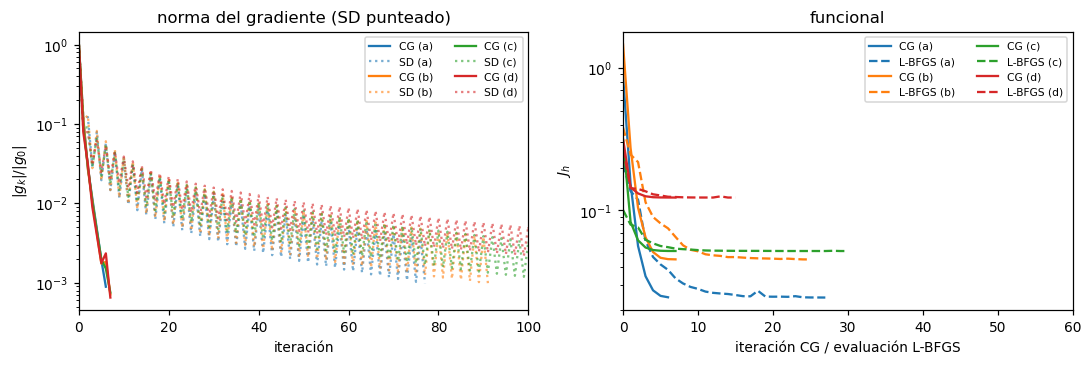

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c, r in results.items():
    l, = ax[0].semilogy(r["gcg"], "-", label=f"CG ({c})")
    ax[0].semilogy(r["gsd"], ":", color=l.get_color(), alpha=0.6, label=f"SD ({c})")
    l, = ax[1].semilogy(r["hcg"], "-", label=f"CG ({c})")
    ax[1].semilogy(r["hbf"][1:], "--", color=l.get_color(), label=f"L-BFGS ({c})")
ax[0].set(xlabel="iteración", ylabel=r"$\|g_k\|/\|g_0\|$", title="norma del gradiente (SD punteado)", xlim=(0, 100))
ax[1].set(xlabel="iteración CG / evaluación L-BFGS", ylabel=r"$J_h$", title="funcional", xlim=(0, 60))
ax[0].legend(ncol=2, fontsize=7); ax[1].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()

### 6.2 Estados y controles óptimos

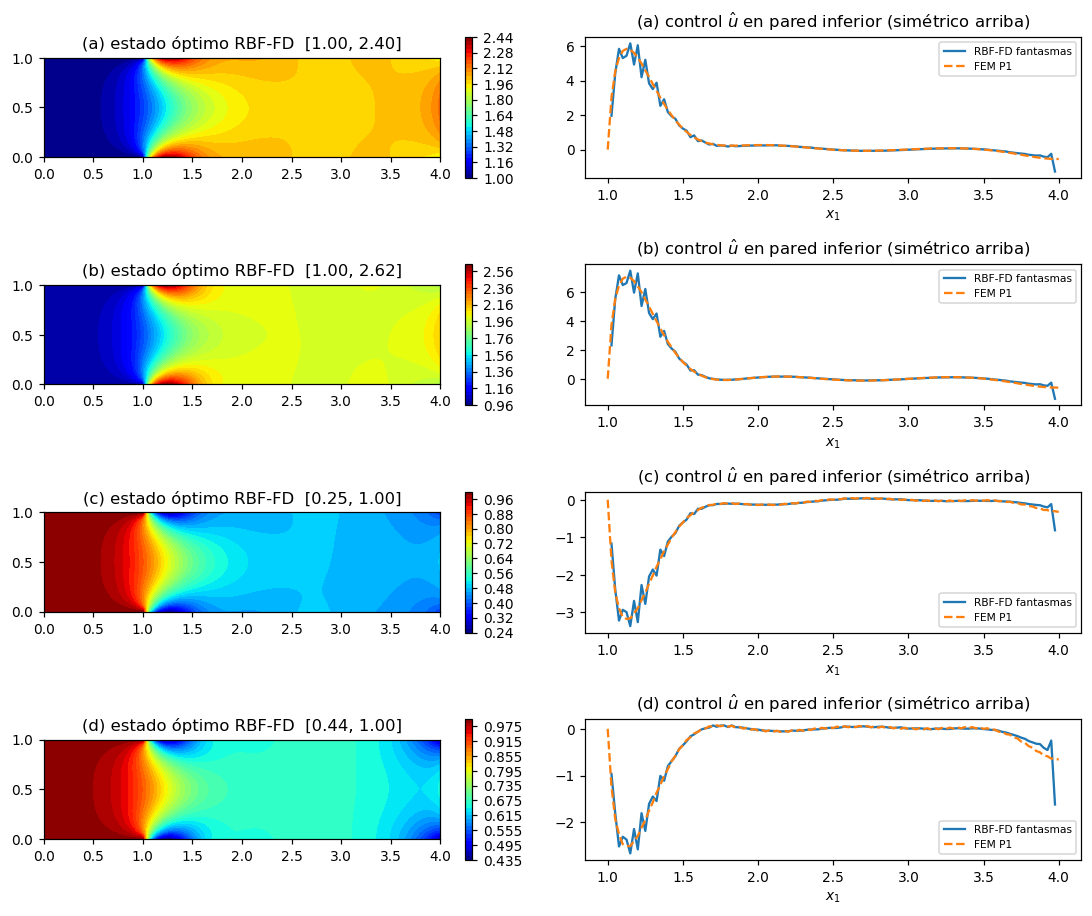

In [11]:
tri = mtri.Triangulation(G.P[:, 0], G.P[:, 1])
fig, axs = plt.subplots(4, 2, figsize=(10, 8.4))
for k, (c, r) in enumerate(results.items()):
    a = axs[k, 0]
    yopt = r["og"].state(r["u_g"])[: G.N]
    tc = a.tricontourf(tri, yopt, 40, cmap="jet"); plt.colorbar(tc, ax=a)
    a.set_title(f"({c}) estado óptimo RBF-FD  [{yopt.min():.2f}, {yopt.max():.2f}]"); a.set_aspect("equal")
    a = axs[k, 1]
    for disc, u, lbl, st in ((G, r["u_g"], "RBF-FD fantasmas", "-"), (F, r["u_f"], "FEM P1", "--")):
        bot = disc.P[disc.ic, 1] < 0.5
        xs = disc.P[disc.ic, 0][bot]; o = np.argsort(xs)
        a.plot(xs[o], u[bot][o], st, label=lbl)
    a.set(title=f"({c}) control $\\hat u$ en pared inferior (simétrico arriba)", xlabel="$x_1$"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

Comparar con la **Fig. 6.5** del libro: en (a) y (b) ($z_d=2$) el control **calienta** las paredes justo después de
$x_1=1$ (pico ≈6) y el «bulbo» caliente se transporta aguas abajo; en (c) y (d) ($z_d=4x_2(1-x_2)$, que vale 0 en
las paredes) el control **enfría**. Las formas coinciden con el libro; las escalas no, porque su estado base no se
reproduce (§1.1). Queda una oscilación residual del control RBF-FD cerca de la esquina $x_1=1$ (unión
Dirichlet–Neumann, donde la solución es singular), que disminuye al refinar (§6.4).

### 6.3 Por qué hacen falta los nodos fantasma: evaluación cruzada

Tomamos el control óptimo de un método y lo **evaluamos en el otro**. Si ambos resuelven el mismo problema continuo,
un buen $\hat u$ debe ser bueno en los dos.

caso    J*_FEM |  J_FEM(û fantasmas) |  J* sin fantasmas  J_FEM(û sin fantasmas)
(a)    0.02424 |             0.02434 |           0.01094                 0.79952
(b)    0.04483 |             0.04496 |           0.02473                 1.37544
(c)    0.05125 |             0.05130 |           0.04897                 0.22333
(d)    0.12253 |             0.12265 |           0.12193                 0.25500


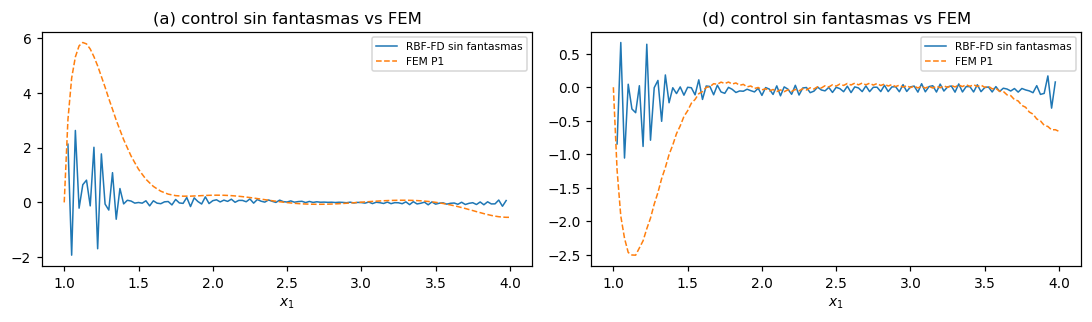

In [12]:
key = lambda P: [tuple(np.round(p, 6)) for p in P]
fpos = {k: i for i, k in enumerate(key(F.P[F.ic]))}


def to_fem(disc, u):
    v = np.zeros(len(F.ic))
    for k, val in zip(key(disc.P[disc.ic]), u):
        v[fpos[k]] = val
    return v


print(f"{'caso':4s} {'J*_FEM':>9s} | {'J_FEM(û fantasmas)':>19s} | {'J* sin fantasmas':>17s} {'J_FEM(û sin fantasmas)':>23s}")
for c, r in results.items():
    of = r["of"]
    print(f"({c})  {of.J(r['u_f']):9.5f} | {of.J(to_fem(G, r['u_g'])):19.5f} | {r['J0']:17.5f} {of.J(to_fem(G0, r['u_0'])):23.5f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, c in zip(ax, ("a", "d")):
    r = results[c]
    for disc, u, lbl, st in ((G0, r["u_0"], "RBF-FD sin fantasmas", "-"), (F, r["u_f"], "FEM P1", "--")):
        bot = disc.P[disc.ic, 1] < 0.5
        xs = disc.P[disc.ic, 0][bot]; o = np.argsort(xs)
        a.plot(xs[o], u[bot][o], st, lw=1, label=lbl)
    a.set(title=f"({c}) control sin fantasmas vs FEM", xlabel="$x_1$"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Sin fantasmas**, el RBF-FD encuentra un $J^*$ *menor* que el FEM (hasta 2.2× menor) con un control pequeño y
oscilante que, metido en el FEM, **casi no reduce** $J$ (0.80 frente a $J(u_0)=0.875$ en el caso a): el optimizador explota modos de alta frecuencia que la colocación de Neumann con
esténcil descentrado amplifica. El gradiente es exacto (Taylor de orden 2) y el estado converge para datos suaves
(§3.1), pero el **problema discreto** está mal aproximado justo en las direcciones que el optimizador busca.
**Con fantasmas** (EDP + condición en el nodo de frontera, esténcil centrado) el control es físico y es bueno en
ambos métodos: $J_{FEM}(\hat u_{RBF})$ queda a menos de 0.5 % del óptimo FEM.

**Lecciones generales:**
1. Un gradiente correcto (Taylor) no garantiza un óptimo correcto: hay que validar el **óptimo** contra una
   discretización independiente.
2. En RBF-FD, las condiciones de Neumann/Robin que tocan el control deben ir con **nodos fantasma** (como ya hace la tesis).
3. La evaluación cruzada $J_{\text{otro}}(\hat u)$ es barata y muy reveladora.

### 6.4 Convergencia en malla (caso a y d)
CG precondicionado con $M_c$: el número de iteraciones no debe crecer al refinar, y el control RBF-FD debe acercarse
al del FEM.

In [13]:
print(f"{'h':6s}{'caso':5s}{'it CG':>6s}{'J* RBF-FD':>11s}{'J* FEM':>10s}{'‖û-û_FEM‖/‖û_FEM‖':>20s}")
for n in (20, 40, 80):
    g = G if n == 40 else RBFFD(1 / n)
    fm = F if n == 40 else FEM(n)
    for c in ("a", "d"):
        o, z = cases[c]
        ug, hg, _ = pcg(OCP(g, o, z)); uf, hf, _ = pcg(OCP(fm, o, z))
        v = np.zeros(len(fm.ic))
        fp = {k: i for i, k in enumerate(key(fm.P[fm.ic]))}
        for k, val in zip(key(g.P[g.ic]), ug):
            v[fp[k]] = val
        rel = np.sqrt((v - uf) @ (fm.Mc @ (v - uf)) / (uf @ (fm.Mc @ uf)))
        print(f"1/{n:<4d}({c})  {len(hg)-1:5d}{hg[-1]:11.5f}{hf[-1]:10.5f}{rel:20.3f}")

h     caso  it CG  J* RBF-FD    J* FEM   ‖û-û_FEM‖/‖û_FEM‖


1/20  (a)      7    0.02740   0.02574               0.161
1/20  (d)      7    0.12582   0.12279               0.177
1/40  (a)      6    0.02462   0.02424               0.071


1/40  (d)      7    0.12324   0.12253               0.119


1/80  (a)      7    0.02381   0.02356               0.047


1/80  (d)      8    0.12260   0.12241               0.089


## 7. Parte B: hacia nuestro problema, control por **tasas de extracción de pozos**

Mismo canal y mismo campo de Graetz, pero ahora el contaminante entra con $y=1$ por $x_1=0$ y queremos **proteger
una zona aguas abajo** $\Omega_{obs}=\{x_1>3.4\}$ extrayendo con $K=4$ pozos. Como en el simulador (sumidero
$Q\,\delta_p\,C$), la extracción **remueve concentración**:

$$
-\mu\Delta y+\mathbf b\cdot\nabla y+\sum_{i=1}^{K}u_i\,\psi_i(x)\,y=0,\qquad
\psi_i(x)=\frac{1}{2\pi\sigma^2}e^{-|x-x_i|^2/2\sigma^2},
$$
con $y=1$ en la entrada ($x_1=0$) y $\mu\partial_n y=0$ en el resto.
$$
\min_{0\le u_i\le u_{\max}} J(u)=\frac12\int_{\Omega_{obs}}y^2\,dx+\frac{\beta}{2}\sum_i u_i^2 .
$$

Diferencias con la Parte A, que son justo las que la acercan a la tesis:
* el control entra **multiplicando al estado** (bilineal) ⇒ $J$ **no es cuadrático** ⇒ CG **no lineal**;
* el control es **finito-dimensional** ($u\in\mathbb R^K$, como $Q_{out}$) y **con cotas** ⇒ proyección;
* es el equivalente estacionario del sumidero del pozo en `step_time` (sin flujo de Darcy acoplado).

> **Nota (revisión del 28-oct-2026, ver `../3_cuadrado_pozo`).** Aquí el pozo es un sumidero $u_i\psi_i\,y$ en el
> transporte, y eso es correcto **porque la velocidad de Graetz no siente el pozo** ($\nabla\cdot\mathbf b=0$). En el
> acuífero de la tesis el pozo sí cambia el flujo ($\nabla\cdot\mathbf q=-Q\delta_p$), y entonces la extracción ya
> está dentro de $\mathbf q\cdot\nabla C$ en la forma no conservativa. Añadir además el sumidero ($W_-$ del
> simulador) cuenta la extracción dos veces. Este modelo de pozo como reacción **no** se traslada tal cual al
> simulador.

Adjunto discreto: $A(u)=A_0+\sum_i u_i S_i$, con $S_i=\operatorname{diag}(m\,\psi_i)$ ($m=1$ en filas de EDP para
colocación, $m=$ masa concentrada para FEM). Entonces
$$A(u)^\top p=M_{obs}\,y,\qquad \frac{\partial J}{\partial u_i}=-p^\top(S_i\,y)+\beta u_i .$$

In [14]:
class Wells:
    """Problema de pozos (Parte B), independiente de la discretización (RBF-FD o FEM, kind='canal')."""

    def __init__(self, disc, xw, sigma=0.08, beta=1e-4):
        self.d, self.beta, self.xw = disc, beta, np.array(xw)
        psi = np.array([np.exp(-((disc.P - c) ** 2).sum(1) / (2 * sigma**2)) / (2 * np.pi * sigma**2) for c in xw])
        self.S = np.array([disc.pad(disc.node_mass()[: disc.N] * p) for p in psi])  # diagonales S_i
        self.Mobs = disc.M0("pozos")
        self.nsolves = 0

    def _lu(self, u):
        return spla.splu((self.d.A + sp.diags(u @ self.S)).tocsc())

    def J(self, u):
        y = self._lu(u).solve(self.d.f); self.nsolves += 1
        return 0.5 * y @ (self.Mobs @ y) + 0.5 * self.beta * u @ u

    def Jg(self, u):
        lu = self._lu(u); y = lu.solve(self.d.f)
        p = lu.solve(self.Mobs @ y, trans="T"); self.nsolves += 2
        J = 0.5 * y @ (self.Mobs @ y) + 0.5 * self.beta * u @ u
        return J, -(self.S * y) @ p + self.beta * u, y


xw = [(1.5, 0.5), (2.0, 0.3), (2.0, 0.7), (2.6, 0.5)]
GB = RBFFD(1 / 40, kind="canal", bc="libre")
WP = Wells(GB, xw)
umax = 5.0

# Taylor
u = np.full(4, 1.0); du = np.array([0.3, -0.2, 0.5, 0.1])
J0, g0, _ = WP.Jg(u)
res = np.array([abs(WP.J(u + e * du) - J0 - e * g0 @ du) for e in 10.0 ** -np.arange(1, 6)])
print("Taylor pozos, tasas:", np.round(np.log10(res[:-1] / res[1:]), 2))

Taylor pozos, tasas: [1.99 2.   2.   2.  ]


### 7.1 CG no lineal proyectado (Polak–Ribière+ con conjunto activo)
```
g_r = gradiente con componentes activas en cero;  d0 = −g_r
repetir:
  α: búsqueda de Wolfe fuerte por secante sobre φ'(α)=∇J(u+αd)·d, truncada en α_max (primera cota)
  si se tocó una cota → reinicio d = −g_r      (el subespacio cambió, la conjugación se pierde)
  si no → β_PR+ = max(0, g_r,newᵀ(g_r,new−g_r)/g_rᵀg_r),  d = −g_r,new + β_PR+ d
  parar si ‖Proj(u−∇J)−u‖ / ‖Proj(u0−∇J0)−u0‖ < tol
```
**Lección aprendida en la práctica:** con backtracking de Armijo solo, el CG no lineal pierde la conjugación. En este
problema (4 pozos, dos simétricos y casi redundantes ⇒ Hessiano mal condicionado) agotó 200 iteraciones sin
converger. CG **necesita** una búsqueda lineal casi exacta (Wolfe fuerte con $c_2$ pequeño).

In [15]:
def proj(u):
    return np.clip(u, 0.0, umax)


def active(u, g):
    """Cotas activas: la variable está en la cota y el gradiente la empuja hacia fuera."""
    return ((u <= 0) & (g > 0)) | ((u >= umax) & (g < 0))


def wolfe_secant(prob, u, J, g, d, a, sigma=1e-4, c2=0.1, maxls=12):
    """Búsqueda lineal (Wolfe fuerte) por secante sobre phi'(a) = g(u+a d)·d, truncada en la cota."""
    pos, neg = d > 0, d < 0
    amax = min(np.min((umax - u[pos]) / d[pos], initial=np.inf), np.min(-u[neg] / d[neg], initial=np.inf))
    dphi0 = g @ d
    lo, dlo, hi, dhi = 0.0, dphi0, None, None
    ap, dp = 0.0, dphi0  # punto evaluado anterior (para la secante)
    a = min(a, amax)
    for _ in range(maxls):
        un = proj(u + a * d)
        Jn, gn, _ = prob.Jg(un)
        dphi = gn @ d
        armijo = Jn <= J + sigma * a * dphi0
        if armijo and abs(dphi) <= c2 * abs(dphi0):
            break
        if armijo and dphi < 0:
            if a >= amax:
                break  # tocamos la cota con descenso: aceptar
            lo, dlo = a, dphi
        else:
            hi, dhi = a, dphi
        if hi is None:  # extrapolar con secante entre el punto anterior y el actual, acotado
            a_sec = a - dphi * (a - ap) / (dphi - dp) if dphi > dp else 2 * a
            ap, dp = a, dphi
            a = min(max(a_sec, 1.5 * a), 10 * a, amax)
        else:  # interpolar dentro de [lo, hi]
            a_sec = lo - dlo * (hi - lo) / (dhi - dlo) if dhi > dlo else 0.5 * (lo + hi)
            a = np.clip(a_sec, lo + 0.1 * (hi - lo), hi - 0.1 * (hi - lo))
    return un, Jn, gn, a, a >= amax


def ncg_proj(prob, u0, tol=1e-6, maxit=100):
    """CG no lineal Polak–Ribière+ con conjunto activo de cotas (CG proyectado)."""
    u = proj(u0.copy())
    J, g, _ = prob.Jg(u)
    gr = np.where(active(u, g), 0.0, g)  # gradiente reducido
    d = -gr
    hist = [J]; pg0 = np.linalg.norm(proj(u - g) - u)
    a = 1.0 / np.abs(g).max()  # primer paso: mover ~1 unidad la tasa más sensible
    for k in range(maxit):
        un, Jn, gn, a_acc, hit = wolfe_secant(prob, u, J, g, d, a)
        grn = np.where(active(un, gn), 0.0, gn)
        if hit:  # cambió el conjunto activo -> reinicio en dirección de descenso
            d_new = -grn
        else:
            bpr = max(0.0, grn @ (grn - gr) / (gr @ gr))
            d_new = -grn + bpr * d
            d_new[active(un, gn)] = 0.0
            if grn @ d_new >= 0:
                d_new = -grn
        # paso inicial siguiente (Nocedal–Wright 3.60)
        a = a_acc * (gr @ d) / (grn @ d_new) if grn @ d_new < 0 else 1.0
        u, J, g, gr, d = un, Jn, gn, grn, d_new
        hist.append(J)
        if np.linalg.norm(proj(u - g) - u) / pg0 < tol:
            break
    return u, np.array(hist)


def lbfgsb(prob):
    hist = []
    def fg(v):
        J, g, _ = prob.Jg(v); hist.append(J); return J, g
    r = minimize(fg, np.zeros(len(prob.xw)), jac=True, method="L-BFGS-B", bounds=[(0, umax)] * len(prob.xw),
                 options={"gtol": 1e-10, "ftol": 1e-14})
    return r, np.array(hist)


WP.nsolves = 0
u_ncg, h_ncg = ncg_proj(WP, np.zeros(4)); ns_ncg = WP.nsolves
WP.nsolves = 0
rb, hb = lbfgsb(WP); ns_lb = WP.nsolves
J_0 = WP.J(np.zeros(4))
print(f"J(0) = {J_0:.5e}")
print(f"CG-PR+ proj : u = {np.round(u_ncg, 4)}  J = {h_ncg[-1]:.5e}  it = {len(h_ncg)-1}  solves = {ns_ncg}")
print(f"L-BFGS-B    : u = {np.round(rb.x, 4)}  J = {rb.fun:.5e}  it = {rb.nit}  solves = {ns_lb}")
print(f"reducción de J: {100*(1-h_ncg[-1]/J_0):.2f} %")

J(0) = 3.00000e-01
CG-PR+ proj : u = [0.7495 0.7697 0.7696 0.7711]  J = 1.77391e-04  it = 4  solves = 34
L-BFGS-B    : u = [0.7503 0.7678 0.7678 0.775 ]  J = 1.77389e-04  it = 12  solves = 42
reducción de J: 99.94 %


### 7.2 Validación de la Parte B contra FEM
Mismo problema con el FEM $\mathbb P_1$ (sumidero con masa concentrada) y varias mallas.

In [16]:
for n in (20, 40, 80):
    WF = Wells(FEM(n, kind="canal", bc="libre"), xw)
    u_f, _ = ncg_proj(WF, np.zeros(4))
    print(f"FEM n={n:2d}: u = {np.round(u_f, 4)}  J = {WF.J(u_f):.5e}   (RBF-FD h=1/40: {np.round(u_ncg, 4)})")

FEM n=20: u = [0.7532 0.7726 0.7726 0.7747]  J = 1.79214e-04   (RBF-FD h=1/40: [0.7495 0.7697 0.7696 0.7711])


FEM n=40: u = [0.7492 0.7694 0.7694 0.7707]  J = 1.76773e-04   (RBF-FD h=1/40: [0.7495 0.7697 0.7696 0.7711])


FEM n=80: u = [0.7475 0.7678 0.7678 0.7691]  J = 1.76180e-04   (RBF-FD h=1/40: [0.7495 0.7697 0.7696 0.7711])


Con control **interior** (pozos) RBF-FD y FEM coinciden a menos de 1 %: el sumidero entra suavemente en filas de
EDP y no hay modos espurios que explotar.

### 7.3 Escenario con cotas activas
Bajamos $u_{\max}$ a 0.6 (bombas más chicas que el óptimo libre ≈0.75): el óptimo queda en la frontera de la caja y
el CG proyectado tiene que identificar el conjunto activo.

In [17]:
umax = 0.6
WP.nsolves = 0
u_ncg2, h_ncg2 = ncg_proj(WP, np.zeros(4)); ns2 = WP.nsolves
WP.nsolves = 0
rb2, _ = lbfgsb(WP)
print(f"CG-PR+ proj : u = {np.round(u_ncg2, 4)}  J = {h_ncg2[-1]:.5e}  it = {len(h_ncg2)-1}  solves = {ns2}")
print(f"L-BFGS-B    : u = {np.round(rb2.x, 4)}  J = {rb2.fun:.5e}  it = {rb2.nit}  solves = {WP.nsolves}")
umax = 5.0

CG-PR+ proj : u = [0.6 0.6 0.6 0.6]  J = 2.25524e-04  it = 4  solves = 14
L-BFGS-B    : u = [0.6 0.6 0.6 0.6]  J = 2.25524e-04  it = 1  solves = 4


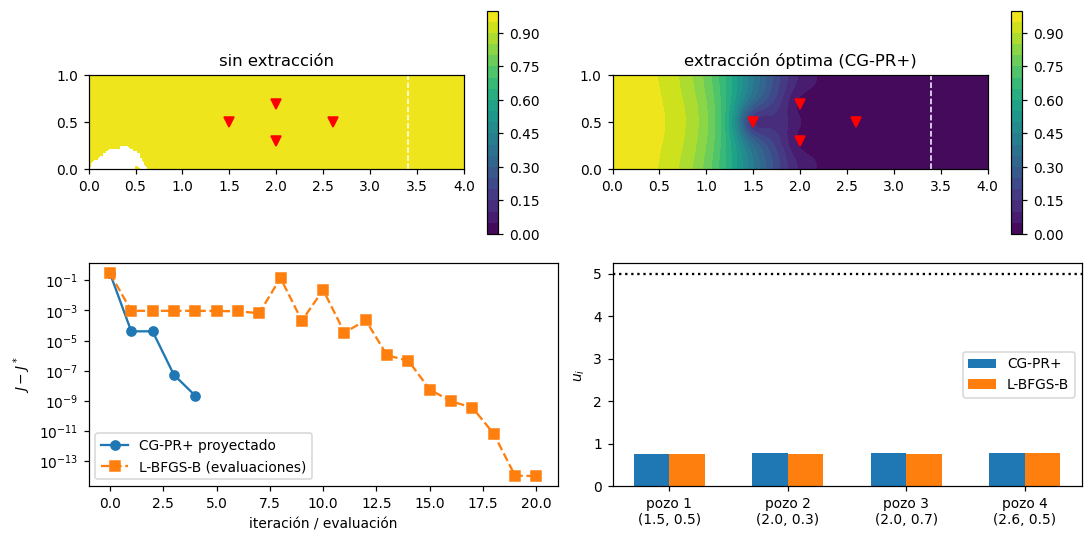

In [18]:
y_0 = WP.Jg(np.zeros(4))[2][: GB.N]; y_opt = WP.Jg(u_ncg)[2][: GB.N]
triB = mtri.Triangulation(GB.P[:, 0], GB.P[:, 1])
fig = plt.figure(figsize=(10, 5))
for k, (yy, ttl) in enumerate([(y_0, "sin extracción"), (y_opt, "extracción óptima (CG-PR+)")]):
    a = fig.add_subplot(2, 2, k + 1)
    tc = a.tricontourf(triB, np.clip(yy, 0, 1), np.linspace(0, 1, 21), cmap="viridis"); plt.colorbar(tc, ax=a)
    a.plot(*WP.xw.T, "rv", ms=6); a.axvline(3.4, color="w", ls="--", lw=1)
    a.set_title(ttl); a.set_aspect("equal")
a = fig.add_subplot(2, 2, 3)
Jstar = min(h_ncg[-1], rb.fun)
a.semilogy(h_ncg - Jstar + 1e-14, "o-", label="CG-PR+ proyectado")
a.semilogy(hb - Jstar + 1e-14, "s--", label="L-BFGS-B (evaluaciones)")
a.set(xlabel="iteración / evaluación", ylabel=r"$J-J^*$"); a.legend()
a = fig.add_subplot(2, 2, 4)
a.bar(np.arange(4) - 0.15, u_ncg, 0.3, label="CG-PR+"); a.bar(np.arange(4) + 0.15, rb.x, 0.3, label="L-BFGS-B")
a.axhline(umax, color="k", ls=":"); a.set_xticks(range(4), [f"pozo {i+1}\n{tuple(c)}" for i, c in enumerate(xw)])
a.set_ylabel("$u_i$"); a.legend()
plt.tight_layout(); plt.show()

## 8. ¿Es un buen caso de estudio?

| Criterio | Graetz (§6.5.1) | Comentario |
|---|---|---|
| Mismo tipo de EDP | ✔ advección–difusión, $\operatorname{div}\mathbf b=0$ | el operador de transporte de la tesis sin MRMT ni término temporal |
| Estructura de optimalidad | ✔ adjunto con advección invertida ($-\mathbf b\cdot\nabla p$), observación parcial $\Omega_0$, Tikhonov $\beta$ | idéntica a la de la tesis (Remark 5.10 / ec. 5.116) |
| Resultado publicado comparable | ✖ parcialmente: tabla incoherente, estado base no reproducible | se suple con un **FEM independiente** (más valioso que una tabla) |
| Revela trampas reales de RBF-FD | ✔✔ lectura de la condición de frontera, Neumann sin fantasmas, DtO exacto pero óptimo espurio | todas aplican al acuífero |
| Tipo de control | ✖ frontera (tesis: pozos interiores) | cubierto por la Parte B, validada con FEM |
| Transitorio / Darcy / MRMT / multiobjetivo | ✖ | siguientes peldaños (§9) |
| Costo | ✔ segundos por corrida | permite experimentar mucho |

**Veredicto:** sí, como **primer peldaño**. No por la tabla del libro, que no sirve como referencia numérica, sino
porque es el problema más simple con la **misma estructura** que el nuestro y obliga a construir y validar todas las
piezas (discretización, condiciones de frontera, adjunto, producto escalar, CG). Además, el control de frontera fue
un «detector» excelente del problema de Neumann sin fantasmas. Por sí solo no basta: la Parte B y los peldaños de §9
son necesarios.

## 9. Receta replicable y escalera de peldaños

**Receta (aplicar en cada peldaño):**
1. **Formular** estado, funcional, control y cotas; fijar la lectura **exacta** de cada condición de frontera.
2. **Buena colocación**: coercividad / signo de $\mathbf b\cdot\mathbf n$ con la condición tal como se discretiza.
3. **Discretizar** con RBF-FD (fantasmas en Neumann) y escribir una **referencia independiente** (FEM simple).
4. **Verificar el estado**: solución manufacturada (orden) y RBF-FD vs referencia.
5. **Adjunto DtO** ($A^\top p=\partial_yJ$) y **test de Taylor** (orden 2).
6. **Producto escalar** del control ($M_c$, $\Delta t$, …) ⇒ precondicionador del CG.
7. **Optimizar**: CG lineal si es cuadrático; CG-PR+ con Wolfe + conjunto activo si no; L-BFGS(-B) como control.
8. **Validar el óptimo**: evaluación cruzada $J_{\text{ref}}(\hat u)$ y convergencia en malla del control.
9. **Comparar con la literatura** sólo después de 1–8, y con espíritu crítico.

**Escalera hacia la tesis:**

| Peldaño | Problema | Lo nuevo | Referencia |
|---|---|---|---|
| 1 ✔ | Graetz, control de frontera | adjunto, CG, fantasmas | libro §6.5.1 + FEM propio |
| 2 ✔ | canal + 4 pozos estacionario | control bilineal, cotas, CG no lineal | FEM propio |
| 3 | calor transitorio, control distribuido | Crank–Nicolson, adjunto hacia atrás, producto en tiempo | libro §8.3, Tablas 8.2–8.3 (J y nº de iteraciones) |
| 4 | peldaño 2 transitorio con $u_i(t)$ | $\partial J/\partial u_i^n=-\Delta t\,(p^{n})^\top S_i y^{n}$ | FEM propio |
| 5 | + Darcy acoplado ($\mathbf b=-K\nabla h(u)$) | adjunto de la carga (`make_adj_H_operator`) | simulador BFR vs FEniCS |
| 6 | + MRMT | adjunto de zonas inmóviles | simulador (Taylor 6/6) |

## 10. Qué trasladar al simulador de la tesis

| Aspecto | Hallazgo aquí | Simulador | Acción recomendada |
|---|---|---|---|
| Neumann + control | sin fantasmas ⇒ óptimo espurio | ya usa nodos fantasma | conservarlos; verificar que **todas** las filas Neumann/Robin los usen |
| Validación | Taylor no basta | Taylor 6/6, BFR vs FEniCS en el estado | añadir evaluación cruzada del **óptimo** (BFR ↔ FEniCS) |
| Optimizador | CG ≈ L-BFGS ≪ SD; CG-PR+ necesita Wolfe | `optimize_bfr` usa `trust-constr`; `nonlinear_cg` (`view/animation.py:437`, PR+) sin uso, con `line_search` **sólo Armijo** (`:398`) y **sin cotas** | portar `wolfe_secant` + conjunto activo a `nonlinear_cg` y compararlo con `trust-constr` en un config aparte (**sin tocar `default.json`**) |
| Producto escalar | $M_c$ ⇒ independencia de malla | $Q(t)$ y $z_p$ con escalas muy distintas | escalar con pesos de cuadratura temporal ($\Delta t$) y adimensionalizar $z_p$ |
| Restricción de suministro | — | lineal (`supply_constraint`) | CG proyectado sólo maneja cajas: penalización o Lagrangiano aumentado, o mantener `trust-constr` |

## 11. Benchmark de referencia (eficiente y reproducible)

El caso se congeló como **benchmark** en tres archivos junto a este notebook:

| Archivo | Contenido |
|---|---|
| `graetz_nucleo.py` | las mismas discretizaciones y optimizadores de este notebook, con ensamblado vectorizado |
| `graetz_referencia.json` | valores de referencia del problema continuo e instantánea de regresión de $h=1/40$ |
| `graetz_benchmark.py` | lanzador: nivel rápido (~10 s, criterios OK/FALLA), `--convergencia`, `--referencia`, `--congelar` |

**Eficiencia.** En una retícula uniforme casi todos los esténciles son traslaciones de unos pocos patrones; los pesos
RBF-FD se calculan sólo para los patrones distintos (exacto: la matriz coincide con la de §2.1 a $10^{-11}$). El
ensamblado en $h=1/80$ pasa de 20 s a ≈1 s más la factorización LU, que ahora domina.

**Por qué hacía falta una referencia mejor.** En retícula uniforme $J(u_0)$ converge a 7 dígitos, pero $J^*$ sólo con
**orden 1** (FEM: 0.02424 → 0.02345 → 0.02313 → 0.02298 para $n=40\ldots320$). La causa es la unión
Dirichlet–Neumann en $(1,0)$ y $(1,1)$: sin control los datos son compatibles ($y\equiv1$ cerca), pero el control
óptimo inyecta flujo justo al lado del nodo Dirichlet y el estado desarrolla una singularidad tipo $r^{1/2}$.
Con una retícula FEM **graduada** hacia esas esquinas ($x=a+(b-a)s^q$, $q=2$) se recupera orden ≈2 y basta
Richardson con $n=80,160,320$. Contraste independiente con $q=3$: coincide a $5\cdot10^{-5}$ relativo.

**Otra corrección:** con tolerancia $10^{-3}$ en $\|g_k\|/\|g_0\|$ (§5–6) el CG para en 6–7 iteraciones pero deja
$J^*$ ≈0.5 % por encima del óptimo discreto. El benchmark usa $10^{-6}$ (19 iteraciones, 60 resoluciones).

**Refinamiento local de RBF-FD: caso negativo.** Graduar la retícula tensorialmente hace divergir el RBF-FD (esténciles
anisótropos). Añadir subretículas isótropas $h/2,h/4,\ldots$ alrededor de las esquinas (`RBFFD(..., ref=k)`) deja el
estado igual de exacto (solución manufacturada), pero el **óptimo es espurio**: $J^*_{RBF}$ baja a 0.0188 (< referencia
0.0228), el control tiene picos de ≈13 (FEM: 6) y, evaluado en el FEM, da $J$ 3× peor. Es el mismo mecanismo que
Neumann sin fantasmas (§6.3): la evaluación cruzada lo detecta de inmediato. Implicación para el simulador: refinar
alrededor de los pozos es seguro con control interior (Parte B), pero cualquier control en frontera Neumann con
espaciado variable exige validación cruzada del óptimo.

In [19]:
import graetz_benchmark as gb
import json
ref = json.loads(gb.REF.read_text())
for c, e in ref["graetz"].items():
    print(f"({c}) J(u0) = {e['J0']['valor']:.6f}   J* = {e['J']['valor']:.6f} ± {e['J']['error_estimado_n320']:.0e}"
          f"   orden {e['J']['orden']:.2f}   (q=3, n=320: {e['J_q3_n320']:.6f})")
t0 = time.time()
r = gb.nivel(40, ref)
print("\nRESULTADO:", "OK" if not gb.verificar(r, ref) else gb.verificar(r, ref), f"({time.time() - t0:.1f}s)")

(a) J(u0) = 0.875023   J* = 0.022827 ± 5e-06   orden 1.75   (q=3, n=320: 0.022828)
(b) J(u0) = 1.458711   J* = 0.042639 ± 7e-06   orden 1.75   (q=3, n=320: 0.042642)
(c) J(u0) = 0.310934   J* = 0.050849 ± 1e-06   orden 2.13   (q=3, n=320: 0.050843)
(d) J(u0) = 0.315367   J* = 0.122294 ± 4e-07   orden 2.21   (q=3, n=320: 0.122293)



h = 1/40: RBF-FD 6601 nodos (+279 fantasmas) en 0.36s | FEM graduado q=2: 6601 vértices en 0.04s
caso     J*_ref |     J*_RBF   err%  it solv |     J*_FEM   err%  it | J_FEM(û_RBF)     Δ%  ‖û_RBF-û_FEM‖%


(a)    0.022827 |   0.024484   7.26  19   60 |   0.022996   0.74  13 |     0.023394   1.73             9.5
(b)    0.042639 |   0.045174   5.95  19   60 |   0.042904   0.62  13 |     0.043742   1.95            10.2


(c)    0.050849 |   0.051948   2.16  19   60 |   0.050731  -0.23  13 |     0.050804   0.14             9.9
(d)    0.122294 |   0.123215   0.75  19   60 |   0.122254  -0.03  13 |     0.122360   0.09            14.1


pozos: J* = 1.773907e-04 (ref 1.759836e-04, err 0.80 %)  u = [0.7495 0.7697 0.7696 0.7711] (ref [0.7476 0.7656 0.7656 0.7726])  it = 4  solves = 34  4.36s

RESULTADO: OK (5.6s)


**Resumen de la convergencia** (`python3 graetz_benchmark.py --convergencia`, error relativo de $J^*$ contra la
referencia; la evaluación cruzada es $J_{FEM}(\hat u_{RBF})/J^*_{FEM}-1$ en el FEM graduado de la misma $h$):

| $h$ | RBF-FD (a) | (b) | (c) | (d) | FEM $q=2$ (a) | cruzada (a) | pozos RBF-FD |
|---|---|---|---|---|---|---|---|
| 1/20 | 19.4 % | 15.3 % | 7.6 % | 2.9 % | 2.4 % | 9.0 % | 1.9 % |
| 1/40 | 7.3 % | 6.0 % | 2.2 % | 0.8 % | 0.7 % | 1.7 % | 0.8 % |
| 1/80 | 3.9 % | 3.2 % | 0.8 % | 0.2 % | 0.2 % | 1.1 % | 0.2 % |

El RBF-FD uniforme converge al valor correcto con orden ≈1–1.5 (como el FEM uniforme: es la singularidad, no el
método). Los casos (a)–(b), con $z_d=2$, son los que más control inyectan cerca de la esquina y los más afectados. Con
control interior (pozos) el orden es ≈1.5–2 sin trucos.

*Referencias:* Manzoni, Quarteroni & Salsa (2021), §1.3, §5.6 (ecs. 5.112–5.116), §6.2.4, §6.5.1 (ecs. 6.64–6.65,
Tabla 6.2, Figs. 6.3–6.5), §8.3 (Tablas 8.2–8.3); Nocedal & Wright (2006) para CG no lineal y Wolfe; Tröltzsch (2010)
para métodos proyectados con cotas.